# 6BUIS017W CWK1 – Task 2: Stock Segmentation and Sensitivity Analysis
Input: outputs/feature_table_task1.csv from the Task 1 notebook (486 shares, common valid set).
Clustering code adapted from the Week 3/4 tutorials (StandardScaler, log1p, Ward linkage, dendrograms, correlations)
and the Week 2 RFM K-means tutorial.

In [9]:
from google.colab import drive
drive.mount("/content/drive")
os.makedirs("/content/drive/MyDrive/crm_cw_task2", exist_ok=True)
os.chdir("/content/drive/MyDrive/crm_cw_task2")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [1]:
# Setup
import os, json, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
for folder in ["outputs", "figures"]:
    os.makedirs(folder, exist_ok=True)

SEED = 42             # fixed random seed so K-means gives the same result every run
K_RANGE = range(2, 9) # cluster counts 2 to 8, as required by the brief
MIN_SIZE_PCT = 5      # smallest cluster must hold at least 5% of shares to be profiled sensibly

versions = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
            "scipy": scipy.__version__, "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__}
print(versions)

{'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0'}


In [2]:
# Upload the Task 1 feature table only if it isn't already in outputs/ (e.g. when running from the GitHub repo)
os.makedirs("outputs", exist_ok=True)
if not os.path.exists("outputs/feature_table_task1.csv"):
    from google.colab import files
    uploaded = files.upload()   # choose feature_table_task1.csv
    os.replace(list(uploaded.keys())[0], "outputs/feature_table_task1.csv")
print("Feature table ready:", os.path.exists("outputs/feature_table_task1.csv"))

Shares loaded: 486 | common valid set used for all solutions: 486


,Security,GICS Sector,n_weeks,mean_weekly_return,sd_weekly_return,weekly_beta,beta_se,beta_r2,paired_weeks,last_event_date,R_days,F_events_60,M_traded_value_usd,in_common_set
Ticker,,,,,,,,,,,,,,
MMM,3M,Industrials,207,0.001142,0.037073,0.869079,0.099685,0.270483,207,2024-12-20,11,4,2.599146e+10,True
AOS,A. O. Smith,Industrials,207,0.001991,0.037625,1.042804,0.093414,0.378067,207,2024-12-20,11,2,4.748980e+09,True
ABT,Abbott Laboratories,Health Care,207,0.000971,0.031128,0.583543,0.089120,0.172967,207,2024-12-20,11,1,3.523027e+10,True
ABBV,AbbVie,Health Care,207,0.003749,0.032094,0.425365,0.096571,0.086458,207,2024-12-20,11,3,6.837054e+10,True
ACN,Accenture,Information Technology,207,0.002376,0.036232,1.143300,0.081451,0.490086,207,2024-12-20,11,2,5.199430e+10,True


## 2.1 Feature preparation
Two separate matrices: risk-return (mean weekly return, weekly beta) and trading activity (R, F, log1p M).
Skew and outliers are checked first; log1p is applied to M; each matrix is standardised separately.

                      skew  outliers_|z|>3           min        median           max
mean_weekly_return   0.868               6 -4.000000e-03  3.000000e-03  1.800000e-02
weekly_beta          1.104               2  5.500000e-02  9.510000e-01  3.779000e+00
R_days               3.646              11  4.000000e+00  1.100000e+01  2.220000e+02
F_events_60          0.425               5  0.000000e+00  3.000000e+00  8.000000e+00
M_traded_value_usd  11.684               5  1.297483e+09  1.668382e+10  1.847697e+12
log1p_M              1.079               7  2.098400e+01  2.353800e+01  2.824500e+01

Largest mean_weekly_return: {'SMCI': 0.0178, 'NVDA': 0.0136, 'VRT': 0.0126}

Largest weekly_beta: {'CVNA': 3.7786, 'XYZ': 2.5045, 'COHR': 2.1393}

Largest R_days: {'NVDA': 222, 'WEC': 151, 'COR': 102}

Largest F_events_60: {'CI': 8, 'HSY': 8, 'FOXA': 7}

Largest M_traded_value_usd: {'TSLA': 1847697379221.8428, 'NVDA': 1825336654239.194, 'AAPL': 623303377706.5842}


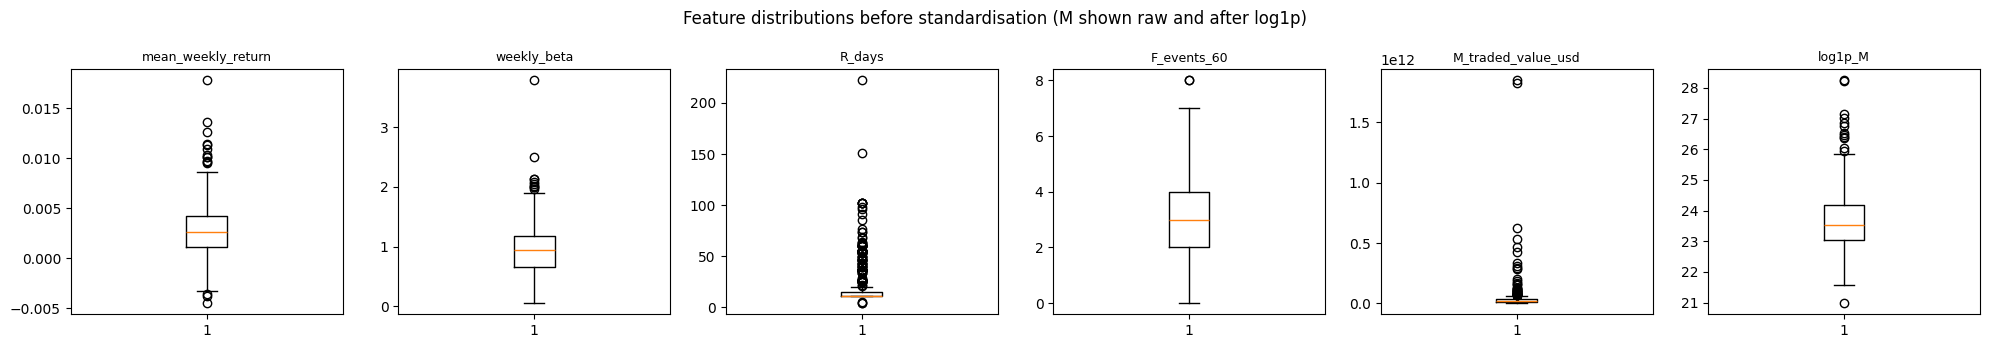

In [3]:
# 2.1a  Skew and outlier diagnostics
data["log1p_M"] = np.log1p(data["M_traded_value_usd"])
raw_cols = ["mean_weekly_return", "weekly_beta", "R_days", "F_events_60", "M_traded_value_usd", "log1p_M"]

def outlier_count(s):
    # number of shares more than 3 standard deviations from the mean
    z = (s - s.mean()) / s.std()
    return int((z.abs() > 3).sum())

diag = pd.DataFrame({
    "skew": data[raw_cols].skew(),
    "outliers_|z|>3": [outlier_count(data[c]) for c in raw_cols],
    "min": data[raw_cols].min(),
    "median": data[raw_cols].median(),
    "max": data[raw_cols].max(),
}).round(3)
diag.to_csv("outputs/t2_skew_outlier_diagnostics.csv")
print(diag.to_string())

# The most extreme shares on each feature (kept, because they are real values, not errors)
for c in ["mean_weekly_return", "weekly_beta", "R_days", "F_events_60", "M_traded_value_usd"]:
    print(f"\nLargest {c}:", data[c].nlargest(3).round(4).to_dict())

# Boxplots before and after the log1p transformation of M
fig, axes = plt.subplots(1, 6, figsize=(20, 3.5))
for ax, c in zip(axes, raw_cols):
    ax.boxplot(data[c])
    ax.set_title(c, fontsize=9)
plt.suptitle("Feature distributions before standardisation (M shown raw and after log1p)")
plt.tight_layout()
plt.savefig("figures/fig3_boxplots_skew.png", dpi=150)
plt.show()

In [4]:
# 2.1b  Two separate feature matrices, standardised
# Matrix 1: risk and return.  Matrix 2: trading activity (R, F, log1p M).
rr_cols = ["mean_weekly_return", "weekly_beta"]
rfm_cols = ["R_days", "F_events_60", "log1p_M"]

X_rr = StandardScaler().fit_transform(data[rr_cols])     # mean 0, standard deviation 1 for each feature
X_rfm = StandardScaler().fit_transform(data[rfm_cols])

check = pd.DataFrame({
    "matrix": ["risk_return"] * 2 + ["rfm"] * 3,
    "feature": rr_cols + rfm_cols,
    "mean_after_scaling": np.r_[X_rr.mean(0), X_rfm.mean(0)].round(6),
    "sd_after_scaling": np.r_[X_rr.std(0), X_rfm.std(0)].round(6),
})
print(check.to_string(index=False))
print("Risk-return matrix shape:", X_rr.shape, "| RFM matrix shape:", X_rfm.shape)

     matrix            feature  mean_after_scaling  sd_after_scaling
risk_return mean_weekly_return                -0.0               1.0
risk_return        weekly_beta                -0.0               1.0
        rfm             R_days                -0.0               1.0
        rfm        F_events_60                -0.0               1.0
        rfm            log1p_M                -0.0               1.0
Risk-return matrix shape: (486, 2) | RFM matrix shape: (486, 3)


In [5]:
# Helper: evaluate k = 2..8 for Ward and K-means
def size_info(labels):
    sizes = pd.Series(labels).value_counts().sort_index()
    return "/".join(str(v) for v in sizes.values), sizes.min()

def evaluate_ward(X, Z):
    rows = []
    for k in K_RANGE:
        labels = fcluster(Z, k, criterion="maxclust")
        sizes, smallest = size_info(labels)
        rows.append({"k": k, "silhouette": silhouette_score(X, labels), "cluster_sizes": sizes,
                     "smallest_pct": 100 * smallest / len(labels)})
    return pd.DataFrame(rows).set_index("k")

def evaluate_kmeans(X):
    rows = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)   # 50 different starting points
        sizes, smallest = size_info(km.labels_)
        rows.append({"k": k, "silhouette": silhouette_score(X, km.labels_), "inertia": km.inertia_,
                     "cluster_sizes": sizes, "smallest_pct": 100 * smallest / len(km.labels_)})
    return pd.DataFrame(rows).set_index("k")

## 2.2 Agglomerative clustering (Ward linkage, Euclidean distance)

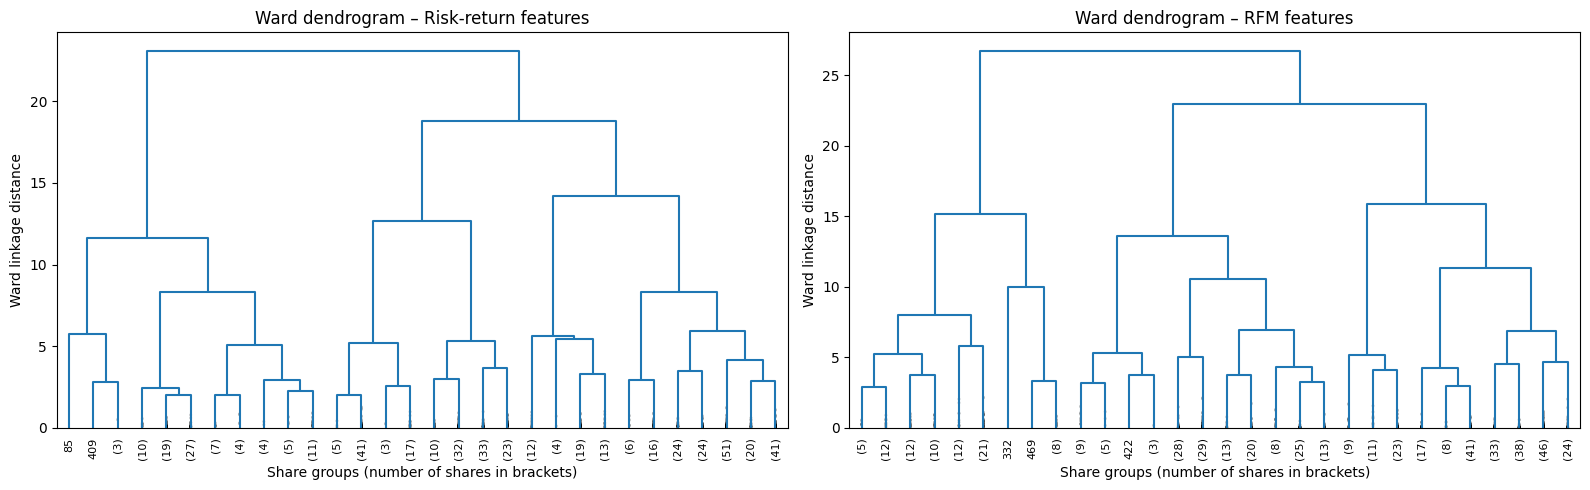

Risk-return: top merge heights (k=1..8 boundaries): [23.07 18.8  14.21 12.67 11.6   8.34  8.31  5.93]
RFM: top merge heights (k=1..8 boundaries): [26.71 22.99 15.84 15.15 13.58 11.29 10.54  9.97]


In [6]:
# 2.2a  Ward linkage (Euclidean distance) and dendrograms
Z_rr = linkage(X_rr, method="ward", metric="euclidean")
Z_rfm = linkage(X_rfm, method="ward", metric="euclidean")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, Z, title in [(axes[0], Z_rr, "Risk-return features"), (axes[1], Z_rfm, "RFM features")]:
    # 486 leaves are unreadable, so only the last 30 merges are shown (labels give group sizes)
    dendrogram(Z, truncate_mode="lastp", p=30, show_contracted=True, leaf_rotation=90,
               leaf_font_size=8, ax=ax, color_threshold=0)
    ax.set_title(f"Ward dendrogram – {title}")
    ax.set_xlabel("Share groups (number of shares in brackets)")
    ax.set_ylabel("Ward linkage distance")
plt.tight_layout()
plt.savefig("figures/fig4_dendrograms.png", dpi=150)
plt.show()

# Big jumps in merge height hint at natural cut points (supporting evidence only)
for name, Z in [("Risk-return", Z_rr), ("RFM", Z_rfm)]:
    heights = Z[-8:, 2][::-1]          # heights of the last merges, top of the tree first
    print(f"{name}: top merge heights (k=1..8 boundaries):", np.round(heights, 2))

In [7]:
# 2.2b  Ward: compare k = 2..8
ward_rr = evaluate_ward(X_rr, Z_rr)
ward_rfm = evaluate_ward(X_rfm, Z_rfm)
ward_rr.to_csv("outputs/t2_ward_k_risk_return.csv")
ward_rfm.to_csv("outputs/t2_ward_k_rfm.csv")
print("Ward – risk-return\n", ward_rr.round(3).to_string())
print("\nWard – RFM\n", ward_rfm.round(3).to_string())

Ward – risk-return
    silhouette            cluster_sizes  smallest_pct
k                                                   
2       0.339                   92/394        18.930
3       0.274               92/164/230        18.930
4       0.282            92/164/48/182         9.877
5       0.304          92/66/98/48/182         9.877
6       0.320        5/87/66/98/48/182         1.029
7       0.324     5/87/66/98/48/22/160         1.029
8       0.321  5/56/31/66/98/48/22/160         1.029

Ward – RFM
    silhouette             cluster_sizes  smallest_pct
k                                                    
2       0.368                    82/404        16.872
3       0.304                82/154/250        16.872
4       0.289             82/154/43/207         8.848
5       0.305          72/10/154/43/207         2.058
6       0.314       72/10/18/136/43/207         2.058
7       0.292    72/10/18/136/43/66/141         2.058
8       0.302  72/10/18/57/79/43/66/141         2.058


## 2.3 K-means clustering (random seed fixed, 50 initialisations)

In [8]:
# 2.3a  K-means: compare k = 2..8
km_rr = evaluate_kmeans(X_rr)
km_rfm = evaluate_kmeans(X_rfm)
km_rr.to_csv("outputs/t2_kmeans_k_risk_return.csv")
km_rfm.to_csv("outputs/t2_kmeans_k_rfm.csv")
print("K-means – risk-return\n", km_rr.round(3).to_string())
print("\nK-means – RFM\n", km_rfm.round(3).to_string())

K-means – risk-return
    silhouette  inertia            cluster_sizes  smallest_pct
k                                                            
2       0.387  621.634                  143/343        29.424
3       0.329  461.179              202/165/119        24.486
4       0.327  371.577           132/154/40/160         8.230
5       0.341  309.613        112/166/131/27/50         5.556
6       0.335  265.097      156/127/50/105/43/5         1.029
7       0.328  227.182    103/85/41/128/77/47/5         1.029
8       0.354  194.362  136/43/76/78/5/29/40/79         1.029

K-means – RFM
    silhouette   inertia             cluster_sizes  smallest_pct
k                                                              
2       0.423  1066.832                    418/68        13.992
3       0.325   796.614                270/152/64        13.169
4       0.341   609.832             122/61/212/91        12.551
5       0.358   514.714          68/122/87/11/198         2.263
6       0.347   437

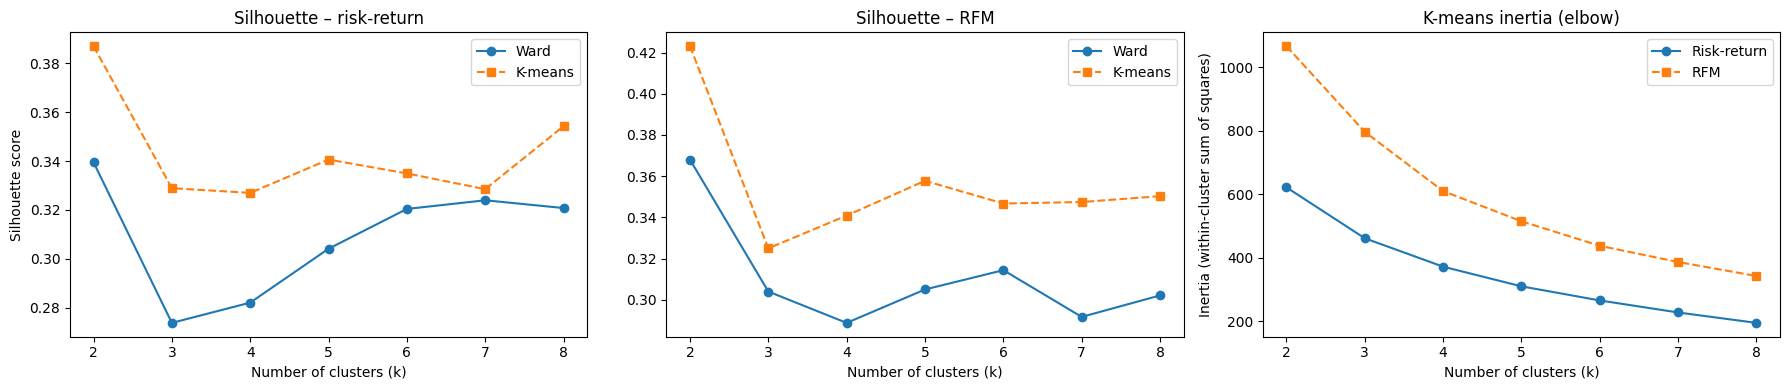

In [9]:
# 2.2c / 2.3b  Diagnostic plots: silhouette and inertia (elbow)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(list(K_RANGE), ward_rr["silhouette"], "o-", label="Ward")
axes[0].plot(list(K_RANGE), km_rr["silhouette"], "s--", label="K-means")
axes[0].set_title("Silhouette – risk-return")
axes[1].plot(list(K_RANGE), ward_rfm["silhouette"], "o-", label="Ward")
axes[1].plot(list(K_RANGE), km_rfm["silhouette"], "s--", label="K-means")
axes[1].set_title("Silhouette – RFM")
axes[2].plot(list(K_RANGE), km_rr["inertia"], "o-", label="Risk-return")
axes[2].plot(list(K_RANGE), km_rfm["inertia"], "s--", label="RFM")
axes[2].set_title("K-means inertia (elbow)")
for ax in axes:
    ax.set_xlabel("Number of clusters (k)")
    ax.legend()
axes[0].set_ylabel("Silhouette score")
axes[2].set_ylabel("Inertia (within-cluster sum of squares)")
plt.tight_layout()
plt.savefig("figures/fig5_k_diagnostics.png", dpi=150)
plt.show()

In [10]:
# Choose one k per matrix
# Rule: highest average silhouette of Ward and K-means, among k where BOTH methods keep every
# cluster at >= 5% of shares (very small clusters can't be profiled reliably).
# Using one k per matrix lets the two algorithms be compared directly on the same shares.
def choose_k(ward_tbl, km_tbl):
    t = pd.DataFrame({"ward_sil": ward_tbl["silhouette"], "km_sil": km_tbl["silhouette"],
                      "ward_small%": ward_tbl["smallest_pct"], "km_small%": km_tbl["smallest_pct"]})
    t["avg_sil"] = t[["ward_sil", "km_sil"]].mean(axis=1)
    t["eligible"] = (t["ward_small%"] >= MIN_SIZE_PCT) & (t["km_small%"] >= MIN_SIZE_PCT)
    best = t.loc[t["eligible"], "avg_sil"].idxmax() if t["eligible"].any() else t["avg_sil"].idxmax()
    return int(best), t.round(3)

K_RR, sel_rr = choose_k(ward_rr, km_rr)
K_RFM, sel_rfm = choose_k(ward_rfm, km_rfm)

# Optional manual override after looking at the profiles (leave as None to keep the rule's choice)
K_RR_OVERRIDE, K_RFM_OVERRIDE = None, None
K_RR = K_RR_OVERRIDE or K_RR
K_RFM = K_RFM_OVERRIDE or K_RFM

print("Risk-return selection table\n", sel_rr.to_string())
print("\nRFM selection table\n", sel_rfm.to_string())
print(f"\nSelected k: risk-return = {K_RR}, RFM = {K_RFM}")

Risk-return selection table
    ward_sil  km_sil  ward_small%  km_small%  avg_sil  eligible
k                                                             
2     0.339   0.387       18.930     29.424    0.363      True
3     0.274   0.329       18.930     24.486    0.301      True
4     0.282   0.327        9.877      8.230    0.305      True
5     0.304   0.341        9.877      5.556    0.322      True
6     0.320   0.335        1.029      1.029    0.328     False
7     0.324   0.328        1.029      1.029    0.326     False
8     0.321   0.354        1.029      1.029    0.338     False

RFM selection table
    ward_sil  km_sil  ward_small%  km_small%  avg_sil  eligible
k                                                             
2     0.368   0.423       16.872     13.992    0.396      True
3     0.304   0.325       16.872     13.169    0.314      True
4     0.289   0.341        8.848     12.551    0.315      True
5     0.305   0.358        2.058      2.263    0.331     False
6   

In [11]:
# Fit the four baseline solutions
def relabel_by(labels, order_values):
    # renumber clusters 1..k by the cluster mean of one feature, so numbering is easy to read
    s = pd.Series(order_values).groupby(labels).mean().sort_values()
    mapping = {old: new for new, old in enumerate(s.index, start=1)}
    return np.array([mapping[l] for l in labels])

assign = pd.DataFrame(index=data.index)
assign["RR_Ward"] = relabel_by(fcluster(Z_rr, K_RR, criterion="maxclust"), data["weekly_beta"].values)
assign["RR_KMeans"] = relabel_by(KMeans(n_clusters=K_RR, n_init=50, random_state=SEED).fit_predict(X_rr),
                                 data["weekly_beta"].values)
assign["RFM_Ward"] = relabel_by(fcluster(Z_rfm, K_RFM, criterion="maxclust"), data["log1p_M"].values)
assign["RFM_KMeans"] = relabel_by(KMeans(n_clusters=K_RFM, n_init=50, random_state=SEED).fit_predict(X_rfm),
                                  data["log1p_M"].values)

# Risk-return clusters are numbered by average beta, RFM clusters by average log1p(M), lowest = 1
full_table = data.join(assign)
full_table.to_csv("outputs/feature_table_with_clusters.csv")
print(assign.apply(lambda c: c.value_counts().sort_index().to_dict()))

RR_Ward        {1: 394, 2: 92}
RR_KMeans     {1: 343, 2: 143}
RFM_Ward       {1: 404, 2: 82}
RFM_KMeans     {1: 418, 2: 68}
dtype: object


In [12]:
# 2.3c  Why multiple initialisations matter (K-means stability check)
def init_check(X, k):
    single = [KMeans(n_clusters=k, n_init=1, random_state=s).fit(X).inertia_ for s in range(20)]
    best = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
    aris = [adjusted_rand_score(best.labels_, KMeans(n_clusters=k, n_init=50, random_state=s).fit_predict(X))
            for s in range(10)]
    return {"k": k, "inertia_n_init_1_min": min(single), "inertia_n_init_1_max": max(single),
            "inertia_n_init_50": best.inertia_, "min_ARI_across_10_seeds": min(aris)}

stability = pd.DataFrame([dict(matrix="risk_return", **init_check(X_rr, K_RR)),
                          dict(matrix="rfm", **init_check(X_rfm, K_RFM))]).round(3)
stability.to_csv("outputs/t2_kmeans_stability.csv", index=False)
print(stability.to_string(index=False))

     matrix  k  inertia_n_init_1_min  inertia_n_init_1_max  inertia_n_init_50  min_ARI_across_10_seeds
risk_return  2               621.634               621.654            621.634                      1.0
        rfm  2              1066.832              1169.902           1066.832                      1.0


## 2.4 Cluster profiles and algorithm comparison

In [13]:
# 2.4a  Cluster profiles in original units
def profile(sol):
    g = full_table.groupby(sol)
    p = pd.DataFrame({
        "n_shares": g.size(),
        "mean_weekly_return_%": g["mean_weekly_return"].mean() * 100,
        "weekly_beta": g["weekly_beta"].mean(),
        "R_days_median": g["R_days"].median(),
        "F_mean": g["F_events_60"].mean(),
        "M_median_$bn": g["M_traded_value_usd"].median() / 1e9,
    }).round(3)
    p.index.name = "cluster"
    return p

profiles = {sol: profile(sol) for sol in ["RR_Ward", "RR_KMeans", "RFM_Ward", "RFM_KMeans"]}
for sol, p in profiles.items():
    print(f"\n{sol}\n{p.to_string()}")
pd.concat(profiles, names=["solution"]).to_csv("outputs/t2_cluster_profiles.csv")


RR_Ward
         n_shares  mean_weekly_return_%  weekly_beta  R_days_median  F_mean  M_median_$bn
cluster                                                                                  
1             394                 0.205        0.898           11.0   2.942        15.325
2              92                 0.632        1.298           11.0   3.196        24.184

RR_KMeans
         n_shares  mean_weekly_return_%  weekly_beta  R_days_median  F_mean  M_median_$bn
cluster                                                                                  
1             343                 0.183        0.817           11.0   2.924        14.206
2             143                 0.533        1.350           11.0   3.147        25.524

RFM_Ward
         n_shares  mean_weekly_return_%  weekly_beta  R_days_median  F_mean  M_median_$bn
cluster                                                                                  
1             404                 0.286        0.967           11.0   

PCA explained variance: [0.458 0.336] | total: 0.794
               PC1    PC2
R_days       0.711  0.023
F_events_60 -0.650  0.402
log1p_M      0.268  0.915


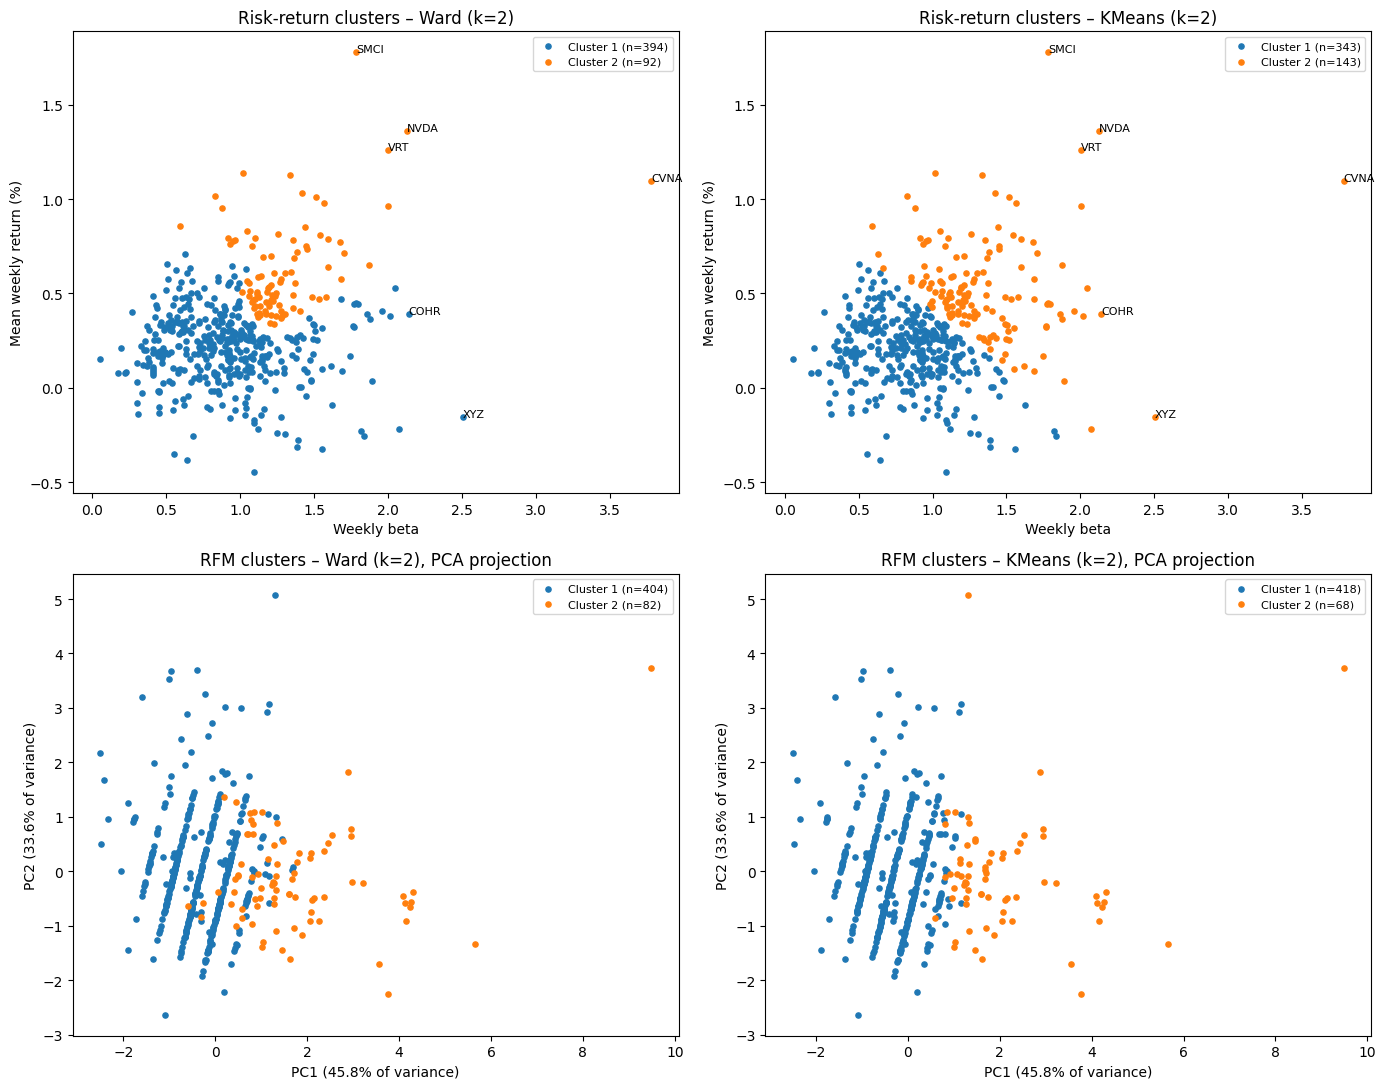

In [14]:
# 2.4b  Labelled two-dimensional visualisations
# Risk-return is already two-dimensional, so it is plotted directly in original units.
# RFM has three features, so PCA reduces the standardised matrix to two components, for plotting only.
pca = PCA(n_components=2, random_state=SEED).fit(X_rfm)
pcs = pca.transform(X_rfm)
expl = pca.explained_variance_ratio_
loadings = pd.DataFrame(pca.components_.T, index=rfm_cols, columns=["PC1", "PC2"]).round(3)
print("PCA explained variance:", np.round(expl, 3), "| total:", round(expl.sum(), 3))
print(loadings)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, sol in zip(axes[0], ["RR_Ward", "RR_KMeans"]):
    for c in sorted(full_table[sol].unique()):
        sub = full_table[full_table[sol] == c]
        ax.scatter(sub["weekly_beta"], sub["mean_weekly_return"] * 100, s=14, label=f"Cluster {c} (n={len(sub)})")
    for t in full_table["weekly_beta"].nlargest(3).index.union(full_table["mean_weekly_return"].nlargest(3).index):
        ax.annotate(t, (full_table.loc[t, "weekly_beta"], full_table.loc[t, "mean_weekly_return"] * 100), fontsize=8)
    ax.set_xlabel("Weekly beta")
    ax.set_ylabel("Mean weekly return (%)")
    ax.set_title(f"Risk-return clusters – {sol.split('_')[1]} (k={K_RR})")
    ax.legend(fontsize=8)
for ax, sol in zip(axes[1], ["RFM_Ward", "RFM_KMeans"]):
    for c in sorted(full_table[sol].unique()):
        mask = (full_table[sol] == c).values
        ax.scatter(pcs[mask, 0], pcs[mask, 1], s=14, label=f"Cluster {c} (n={mask.sum()})")
    ax.set_xlabel(f"PC1 ({expl[0]*100:.1f}% of variance)")
    ax.set_ylabel(f"PC2 ({expl[1]*100:.1f}% of variance)")
    ax.set_title(f"RFM clusters – {sol.split('_')[1]} (k={K_RFM}), PCA projection")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/fig6_cluster_scatter.png", dpi=150)
plt.show()

In [15]:
# 2.4c  Algorithm comparison on the same shares
ari_rr = adjusted_rand_score(assign["RR_Ward"], assign["RR_KMeans"])
ari_rfm = adjusted_rand_score(assign["RFM_Ward"], assign["RFM_KMeans"])
print(f"ARI Ward vs K-means: risk-return = {ari_rr:.3f}, RFM = {ari_rfm:.3f}")
print("\nRisk-return: Ward (rows) vs K-means (columns)\n", pd.crosstab(assign["RR_Ward"], assign["RR_KMeans"]))
print("\nRFM: Ward (rows) vs K-means (columns)\n", pd.crosstab(assign["RFM_Ward"], assign["RFM_KMeans"]))
sil_final = {
    "RR_Ward": silhouette_score(X_rr, assign["RR_Ward"]), "RR_KMeans": silhouette_score(X_rr, assign["RR_KMeans"]),
    "RFM_Ward": silhouette_score(X_rfm, assign["RFM_Ward"]), "RFM_KMeans": silhouette_score(X_rfm, assign["RFM_KMeans"]),
}
print("\nSilhouette of the four selected solutions:", {k: round(v, 3) for k, v in sil_final.items()})

ARI Ward vs K-means: risk-return = 0.598, RFM = 0.700

Risk-return: Ward (rows) vs K-means (columns)
 RR_KMeans    1   2
RR_Ward           
1          343  51
2            0  92

RFM: Ward (rows) vs K-means (columns)
 RFM_KMeans    1   2
RFM_Ward           
1           396   8
2            22  60

Silhouette of the four selected solutions: {'RR_Ward': np.float64(0.339), 'RR_KMeans': np.float64(0.387), 'RFM_Ward': np.float64(0.368), 'RFM_KMeans': np.float64(0.423)}


## 2.5 RFM sensitivity and correlated inputs

Pearson
              R_days  F_events_60  log1p_M
R_days        1.000       -0.346    0.152
F_events_60  -0.346        1.000    0.013
log1p_M       0.152        0.013    1.000 

Spearman (rank-based, less affected by outliers)
              R_days  F_events_60  log1p_M
R_days        1.000       -0.196    0.137
F_events_60  -0.196        1.000   -0.048
log1p_M       0.137       -0.048    1.000


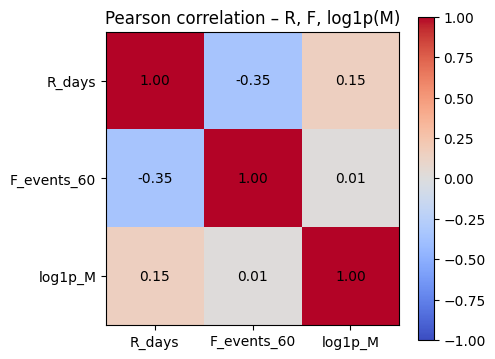

In [16]:
# 2.5.1  Correlations among R, F and log1p(M)
corr_p = data[rfm_cols].corr(method="pearson").round(3)
corr_s = data[rfm_cols].corr(method="spearman").round(3)
print("Pearson\n", corr_p, "\n\nSpearman (rank-based, less affected by outliers)\n", corr_s)
corr_p.to_csv("outputs/t2_rfm_correlation_pearson.csv")
corr_s.to_csv("outputs/t2_rfm_correlation_spearman.csv")

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr_p, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(rfm_cols); ax.set_yticks(range(3)); ax.set_yticklabels(rfm_cols)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr_p.iloc[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im)
ax.set_title("Pearson correlation – R, F, log1p(M)")
plt.tight_layout()
plt.savefig("figures/fig7_rfm_correlation.png", dpi=150)
plt.show()

ARI full RFM Ward vs R+F-only Ward (k=2): 0.873

Full RFM Ward (rows) vs R+F-only Ward (columns)
 RF_Ward    1    2
RFM_Ward         
1         10  394
2         79    3

Traded value profile – full RFM Ward
           n_shares  R_days_median  F_mean  M_median_$bn  M_IQR_$bn
RFM_Ward                                                          
1              404           11.0    3.17         16.05      22.18
2               82           54.5    2.10         17.85      19.48

Traded value profile – R+F only Ward
          n_shares  R_days_median  F_mean  M_median_$bn  M_IQR_$bn
RF_Ward                                                          
1              89           54.0    2.01         20.85      19.51
2             397           11.0    3.21         15.46      22.11

Share of log1p(M) variance explained by clusters: full RFM = 0.001, R+F only = 0.004


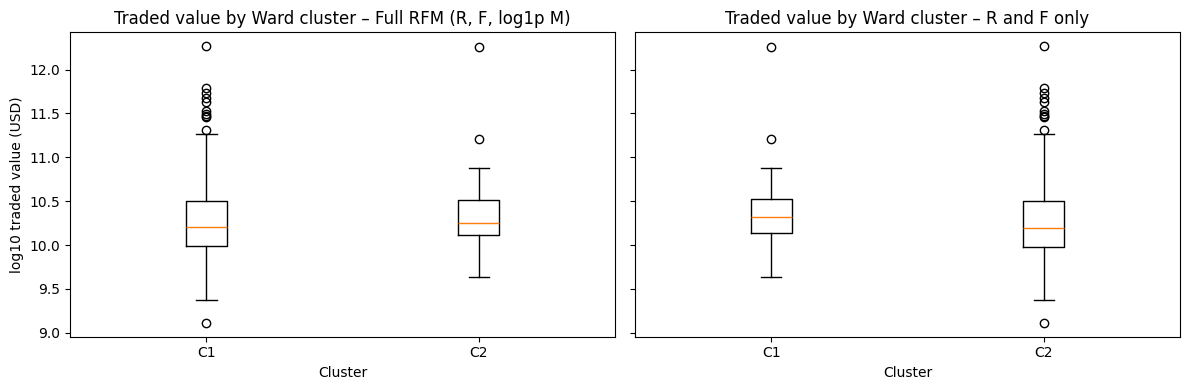

In [17]:
# 2.5.2  Remove Monetary: Ward on R and F only
# Same shares and same k as the selected Ward RFM solution; R and F are standardised again from scratch
X_rf = StandardScaler().fit_transform(data[["R_days", "F_events_60"]])
Z_rf = linkage(X_rf, method="ward", metric="euclidean")
assign["RF_Ward"] = relabel_by(fcluster(Z_rf, K_RFM, criterion="maxclust"), data["F_events_60"].values)
full_table["RF_Ward"] = assign["RF_Ward"]

ari_m = adjusted_rand_score(assign["RFM_Ward"], assign["RF_Ward"])   # unaffected by cluster numbering
print(f"ARI full RFM Ward vs R+F-only Ward (k={K_RFM}): {ari_m:.3f}")
print("\nFull RFM Ward (rows) vs R+F-only Ward (columns)\n", pd.crosstab(assign["RFM_Ward"], assign["RF_Ward"]))

def tv_profile(sol):
    g = full_table.groupby(sol)
    return pd.DataFrame({"n_shares": g.size(), "R_days_median": g["R_days"].median(),
                         "F_mean": g["F_events_60"].mean().round(2),
                         "M_median_$bn": (g["M_traded_value_usd"].median() / 1e9).round(2),
                         "M_IQR_$bn": ((g["M_traded_value_usd"].quantile(.75) - g["M_traded_value_usd"].quantile(.25)) / 1e9).round(2)})
tv_full, tv_rf = tv_profile("RFM_Ward"), tv_profile("RF_Ward")
print("\nTraded value profile – full RFM Ward\n", tv_full)
print("\nTraded value profile – R+F only Ward\n", tv_rf)

# Share of the variation in log1p(M) explained by each solution (eta-squared): higher = clusters separate liquidity more
def eta_sq(sol):
    y = full_table["log1p_M"]
    between = full_table.groupby(sol)["log1p_M"].apply(lambda s: len(s) * (s.mean() - y.mean()) ** 2).sum()
    return between / ((y - y.mean()) ** 2).sum()
print(f"\nShare of log1p(M) variance explained by clusters: full RFM = {eta_sq('RFM_Ward'):.3f}, R+F only = {eta_sq('RF_Ward'):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, sol, title in [(axes[0], "RFM_Ward", "Full RFM (R, F, log1p M)"), (axes[1], "RF_Ward", "R and F only")]:
    groups = [np.log10(full_table.loc[full_table[sol] == c, "M_traded_value_usd"]) for c in sorted(full_table[sol].unique())]
    ax.boxplot(groups)
    ax.set_xticks(range(1, len(groups) + 1))
    ax.set_xticklabels([f"C{c}" for c in sorted(full_table[sol].unique())])
    ax.set_title(f"Traded value by Ward cluster – {title}")
    ax.set_xlabel("Cluster")
axes[0].set_ylabel("log10 traded value (USD)")
plt.tight_layout()
plt.savefig("figures/fig8_monetary_removal.png", dpi=150)
plt.show()

full_table.to_csv("outputs/feature_table_with_clusters.csv")
assign.to_csv("outputs/cluster_assignments.csv")

## Report numbers and report tables
Prints every number used in the Task 2 text and exports the report tables to outputs/report_tables_task2.xlsx.

In [18]:
# Report numbers and report tables
report_numbers = {
    "Shares in common set": len(data),
    "Skew raw M / log1p M": f"{diag.loc['M_traded_value_usd','skew']} / {diag.loc['log1p_M','skew']}",
    "Skew R / F": f"{diag.loc['R_days','skew']} / {diag.loc['F_events_60','skew']}",
    "Skew return / beta": f"{diag.loc['mean_weekly_return','skew']} / {diag.loc['weekly_beta','skew']}",
    "Outliers |z|>3 (ret, beta, R, F, logM)": ", ".join(str(diag.loc[c, "outliers_|z|>3"]) for c in
                                                       ["mean_weekly_return", "weekly_beta", "R_days", "F_events_60", "log1p_M"]),
    "Selected k risk-return / RFM": f"{K_RR} / {K_RFM}",
    "Ward RR silhouette at k": round(ward_rr.loc[K_RR, "silhouette"], 3),
    "KMeans RR silhouette at k": round(km_rr.loc[K_RR, "silhouette"], 3),
    "Ward RFM silhouette at k": round(ward_rfm.loc[K_RFM, "silhouette"], 3),
    "KMeans RFM silhouette at k": round(km_rfm.loc[K_RFM, "silhouette"], 3),
    "Best Ward RR k by silhouette alone": int(ward_rr["silhouette"].idxmax()),
    "Best Ward RFM k by silhouette alone": int(ward_rfm["silhouette"].idxmax()),
    "Sizes RR Ward / KMeans": f"{ward_rr.loc[K_RR,'cluster_sizes']} | {km_rr.loc[K_RR,'cluster_sizes']}",
    "Sizes RFM Ward / KMeans": f"{ward_rfm.loc[K_RFM,'cluster_sizes']} | {km_rfm.loc[K_RFM,'cluster_sizes']}",
    "ARI Ward vs KMeans RR / RFM": f"{ari_rr:.3f} / {ari_rfm:.3f}",
    "KMeans n_init=1 inertia range RR": f"{stability.loc[0,'inertia_n_init_1_min']} to {stability.loc[0,'inertia_n_init_1_max']} (n_init=50: {stability.loc[0,'inertia_n_init_50']})",
    "KMeans n_init=1 inertia range RFM": f"{stability.loc[1,'inertia_n_init_1_min']} to {stability.loc[1,'inertia_n_init_1_max']} (n_init=50: {stability.loc[1,'inertia_n_init_50']})",
    "Min ARI across seeds RR / RFM": f"{stability.loc[0,'min_ARI_across_10_seeds']} / {stability.loc[1,'min_ARI_across_10_seeds']}",
    "PCA variance PC1 / PC2 / total %": f"{expl[0]*100:.1f} / {expl[1]*100:.1f} / {expl.sum()*100:.1f}",
    "Pearson R-F / R-logM / F-logM": f"{corr_p.loc['R_days','F_events_60']} / {corr_p.loc['R_days','log1p_M']} / {corr_p.loc['F_events_60','log1p_M']}",
    "Spearman R-F / R-logM / F-logM": f"{corr_s.loc['R_days','F_events_60']} / {corr_s.loc['R_days','log1p_M']} / {corr_s.loc['F_events_60','log1p_M']}",
    "ARI RFM Ward vs RF-only Ward": round(ari_m, 3),
    "Eta2 log1p M: full RFM / RF only": f"{eta_sq('RFM_Ward'):.3f} / {eta_sq('RF_Ward'):.3f}",
}
for k, v in report_numbers.items():
    print(f"{k:42s}: {v}")
pd.Series(report_numbers).to_csv("outputs/report_numbers_task2.csv")

with pd.ExcelWriter("outputs/report_tables_task2.xlsx") as w:
    diag.reset_index().rename(columns={"index": "Feature"}).to_excel(w, sheet_name="T6_Skew_outliers", index=False)
    ward_rr.round(3).add_prefix("Ward_").join(km_rr.round(3).add_prefix("KMeans_")).reset_index().to_excel(w, sheet_name="T7_k_risk_return", index=False)
    ward_rfm.round(3).add_prefix("Ward_").join(km_rfm.round(3).add_prefix("KMeans_")).reset_index().to_excel(w, sheet_name="T8_k_RFM", index=False)
    stability.to_excel(w, sheet_name="T9_KMeans_stability", index=False)
    for sol in profiles:
        profiles[sol].reset_index().to_excel(w, sheet_name=f"T10_Profile_{sol}", index=False)
    pd.DataFrame({"Comparison": ["Ward vs K-means (risk-return)", "Ward vs K-means (RFM)", "Full RFM Ward vs R+F-only Ward"],
                  "ARI": [round(ari_rr, 3), round(ari_rfm, 3), round(ari_m, 3)]}).to_excel(w, sheet_name="T11_ARI", index=False)
    corr_p.reset_index().to_excel(w, sheet_name="T12_Corr_Pearson", index=False)
    corr_s.reset_index().to_excel(w, sheet_name="T12_Corr_Spearman", index=False)
    tv_full.reset_index().to_excel(w, sheet_name="T13_TV_full_RFM", index=False)
    tv_rf.reset_index().to_excel(w, sheet_name="T13_TV_RF_only", index=False)
    full_table.reset_index()[["Ticker", "Security", "GICS Sector", "RR_Ward", "RR_KMeans", "RFM_Ward", "RFM_KMeans", "RF_Ward"]].head(15).to_excel(w, sheet_name="AppD_Assignments", index=False)
print("Saved outputs/report_tables_task2.xlsx")

Shares in common set                      : 486
Skew raw M / log1p M                      : 11.684 / 1.079
Skew R / F                                : 3.646 / 0.425
Skew return / beta                        : 0.868 / 1.104
Outliers |z|>3 (ret, beta, R, F, logM)    : 6, 2, 11, 5, 7
Selected k risk-return / RFM              : 2 / 2
Ward RR silhouette at k                   : 0.339
KMeans RR silhouette at k                 : 0.387
Ward RFM silhouette at k                  : 0.368
KMeans RFM silhouette at k                : 0.423
Best Ward RR k by silhouette alone        : 2
Best Ward RFM k by silhouette alone       : 2
Sizes RR Ward / KMeans                    : 92/394 | 143/343
Sizes RFM Ward / KMeans                   : 82/404 | 418/68
ARI Ward vs KMeans RR / RFM               : 0.598 / 0.700
KMeans n_init=1 inertia range RR          : 621.634 to 621.654 (n_init=50: 621.634)
KMeans n_init=1 inertia range RFM         : 1066.832 to 1169.902 (n_init=50: 1066.832)
Min ARI across seeds RR / 

## 2.2d Profiles at k = 3 and k = 4
Checks whether extra clusters add meaningful groups or only split off outliers (supports the choice of k).

In [19]:
# 2.2d  Profiles at k = 3 and 4 (do extra clusters add meaning?)
def members(s):
    # small clusters: list every share; large clusters: show the 3 most-traded shares as examples
    return ", ".join(s.index) if len(s) <= 10 else "e.g. " + ", ".join(s.nlargest(3, "M_traded_value_usd").index)

alt_rows = []
for matrix, X, Z in [("risk_return", X_rr, Z_rr), ("rfm", X_rfm, Z_rfm)]:
    for k in [3, 4]:
        for method in ["Ward", "KMeans"]:
            if method == "Ward":
                labels = fcluster(Z, k, criterion="maxclust")
            else:
                labels = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit_predict(X)
            tmp = data.assign(cluster=labels)
            g = tmp.groupby("cluster")
            prof = pd.DataFrame({
                "n_shares": g.size(),
                "mean_weekly_return_%": g["mean_weekly_return"].mean() * 100,
                "weekly_beta": g["weekly_beta"].mean(),
                "R_days_median": g["R_days"].median(),
                "F_mean": g["F_events_60"].mean(),
                "M_median_$bn": g["M_traded_value_usd"].median() / 1e9,
                "members": pd.Series({c: members(tmp[tmp["cluster"] == c]) for c in g.groups}),
            }).round(3).sort_values("n_shares", ascending=False)
            prof.index.name = "cluster"
            print(f"\n{matrix} – {method} – k={k}\n{prof.to_string()}")
            alt_rows.append(prof.reset_index().assign(matrix=matrix, method=method, k=k))

alt = pd.concat(alt_rows, ignore_index=True)
alt = alt[["matrix", "method", "k", "cluster", "n_shares", "mean_weekly_return_%", "weekly_beta",
           "R_days_median", "F_mean", "M_median_$bn", "members"]]
alt.to_csv("outputs/t2_profiles_k3_k4.csv", index=False)
with pd.ExcelWriter("outputs/report_tables_task2.xlsx", mode="a", engine="openpyxl", if_sheet_exists="replace") as w:
    alt.to_excel(w, sheet_name="T14_Profiles_k3_k4", index=False)
print("\nSaved outputs/t2_profiles_k3_k4.csv and sheet T14_Profiles_k3_k4")


risk_return – Ward – k=3
         n_shares  mean_weekly_return_%  weekly_beta  R_days_median  F_mean  M_median_$bn                members
cluster                                                                                                         
3             230                 0.146        1.110           11.0   3.057        14.111   e.g. TSLA, AMZN, AMD
2             164                 0.287        0.601           11.0   2.780        17.649   e.g. UNH, JPM, BRK-B
1              92                 0.632        1.298           11.0   3.196        24.184  e.g. NVDA, AAPL, MSFT

risk_return – KMeans – k=3
         n_shares  mean_weekly_return_%  weekly_beta  R_days_median  F_mean  M_median_$bn                members
cluster                                                                                                         
0             202                 0.259        0.631           11.0   2.911        15.202       e.g. UNH, JPM, V
1             165                 0.095   